In [3]:

%pip install tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Deepan\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [4]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("All required libraries imported successfully!")


NumPy: 2.4.6
TensorFlow: 2.21.0
All required libraries imported successfully!


In [1]:
import zipfile
from pathlib import Path

zip_path = Path("Banana Leaf Spot Diseases.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("BananaLeafDataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
from pathlib import Path

for item in Path("BananaLeafDataset").iterdir():
    print(item.name)

Banana Leaf Spot Diseases (BananaLSD) Dataset for Classification of Banana Leaf Diseases Using Machine Learning


In [9]:

from pathlib import Path

DATA_DIR = Path(
    "BananaLeafDataset/Banana Leaf Spot Diseases (BananaLSD) Dataset for Classification of Banana Leaf Diseases Using Machine Learning/BananaLSD/OriginalSet"
)

print("Dataset path exists:", DATA_DIR.exists())
print("Disease classes:", [folder.name for folder in DATA_DIR.iterdir() if folder.is_dir()])


Dataset path exists: True
Disease classes: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']


In [10]:

from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_folder in sorted(DATA_DIR.iterdir()):
    if class_folder.is_dir():
        images = [
            file for file in class_folder.rglob("*")
            if file.is_file() and file.suffix.lower() in image_extensions
        ]
        print(f"{class_folder.name}: {len(images)} images")

total_images = sum(
    1 for file in DATA_DIR.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
)

print("Total images:", total_images)


cordana: 162 images
healthy: 129 images
pestalotiopsis: 173 images
sigatoka: 473 images
Total images: 937


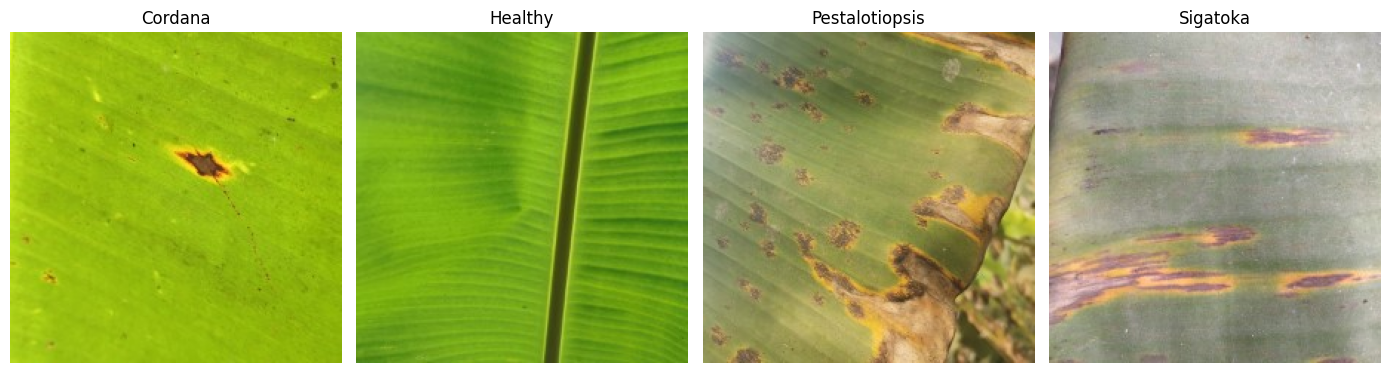

In [11]:

import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

class_names = ["cordana", "healthy", "pestalotiopsis", "sigatoka"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, class_name in zip(axes, class_names):
    class_folder = DATA_DIR / class_name

    image_files = [
        f for f in class_folder.iterdir()
        if f.is_file() and f.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()


In [12]:
from sklearn.model_selection import train_test_split

image_paths = []
image_labels = []

for class_name in class_names:
    class_folder = DATA_DIR / class_name

    for file in class_folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            image_paths.append(str(file))
            image_labels.append(class_name)

In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

In [14]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [15]:
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

Training images: 655
Validation images: 141
Testing images: 141
Total: 937


In [16]:

import numpy as np
from PIL import Image

IMG_SIZE = (128, 128)
BATCH_SIZE = 16

label_map = {
    "cordana": 0,
    "healthy": 1,
    "pestalotiopsis": 2,
    "sigatoka": 3
}

def load_images(paths, labels):
    images = []

    for path in paths:
        with Image.open(path) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)
            images.append(np.array(img, dtype=np.float32) / 255.0)

    encoded_labels = np.array(
        [label_map[label] for label in labels],
        dtype=np.int32
    )

    return np.array(images), encoded_labels

X_train_img, y_train_num = load_images(X_train, y_train)
X_val_img, y_val_num = load_images(X_val, y_val)
X_test_img, y_test_num = load_images(X_test, y_test)

print("Training data:", X_train_img.shape)
print("Validation data:", X_val_img.shape)
print("Testing data:", X_test_img.shape)


C:\Users\Deepan\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\TiffImagePlugin.py:870: UserWarning: Truncated File Read
  warnings.warn(str(msg))
C:\Users\Deepan\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\JpegImagePlugin.py:853: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Training data: (655, 128, 128, 3)
Validation data: (141, 128, 128, 3)
Testing data: (141, 128, 128, 3)


In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,172 (434.27 KB)

 Trainable params: 110,724 (432.52 KB)

 Non-trainable params: 448 (1.75 KB)

In [18]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_num)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_num
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class mapping:", label_map)
print("Class weights:", class_weights)


Class mapping: {'cordana': 0, 'healthy': 1, 'pestalotiopsis': 2, 'sigatoka': 3}
Class weights: {0: 1.4491150442477876, 1: 1.8194444444444444, 2: 1.353305785123967, 3: 0.4947129909365559}


In [20]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    X_train_img,
    y_train_num,
    validation_data=(X_val_img, y_val_num),
    epochs=20,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 206ms/step - accuracy: 0.6992 - loss: 0.8745 - val_accuracy: 0.1418 - val_loss: 1.6860
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 208ms/step - accuracy: 0.7282 - loss: 0.7584 - val_accuracy: 0.1418 - val_loss: 1.9413
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 217ms/step - accuracy: 0.7313 - loss: 0.6793 - val_accuracy: 0.1418 - val_loss: 2.1297
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 216ms/step - accuracy: 0.7847 - loss: 0.6311 - val_accuracy: 0.1418 - val_loss: 2.4755
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 215ms/step - accuracy: 0.8092 - loss: 0.5605 - val_accuracy: 0.1418 - val_loss: 2.9858


In [21]:

from collections import Counter

print("Class mapping:", label_map)
print("Training labels:", Counter(y_train_num))
print("Validation labels:", Counter(y_val_num))
print("Training shape:", X_train_img.shape)
print("Validation shape:", X_val_img.shape)


Class mapping: {'cordana': 0, 'healthy': 1, 'pestalotiopsis': 2, 'sigatoka': 3}
Training labels: Counter({np.int32(3): 331, np.int32(2): 121, np.int32(0): 113, np.int32(1): 90})
Validation labels: Counter({np.int32(3): 71, np.int32(2): 26, np.int32(0): 24, np.int32(1): 20})
Training shape: (655, 128, 128, 3)
Validation shape: (141, 128, 128, 3)


In [22]:

import numpy as np

val_probs = model.predict(X_val_img, verbose=0)
val_preds = np.argmax(val_probs, axis=1)

print("Predicted class counts:", Counter(val_preds))
print("Actual class counts:", Counter(y_val_num))


Predicted class counts: Counter({np.int64(1): 141})
Actual class counts: Counter({np.int32(3): 71, np.int32(2): 26, np.int32(0): 24, np.int32(1): 20})


In [23]:

print("Class weights:", class_weights)
print("Model output classes:", model.output_shape)
print("Loss function:", model.loss)


Class weights: {0: 1.4491150442477876, 1: 1.8194444444444444, 2: 1.353305785123967, 3: 0.4947129909365559}
Model output classes: (None, 4)
Loss function: sparse_categorical_crossentropy


In [24]:

print("Mean probability per class:")
print(np.round(val_probs.mean(axis=0), 4))

print("\nFirst 10 predictions:")
print(val_preds[:10])

print("\nFirst 10 actual labels:")
print(y_val_num[:10])


Mean probability per class:
[0.156  0.523  0.1777 0.1434]

First 10 predictions:
[1 1 1 1 1 1 1 1 1 1]

First 10 actual labels:
[1 2 2 2 0 3 3 3 3 3]


In [25]:

# Check predictions on a small sample of training images
train_probs = model.predict(X_train_img[:32], verbose=0)
train_preds = np.argmax(train_probs, axis=1)

print("Actual training labels:")
print(y_train_num[:32])

print("\nPredicted training labels:")
print(train_preds)

print("\nTraining prediction counts:")
print(Counter(train_preds))


Actual training labels:
[3 1 3 3 2 3 0 3 2 3 0 3 0 0 3 2 3 3 0 3 0 3 2 3 1 3 2 2 2 3 3 1]

Predicted training labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Training prediction counts:
Counter({np.int64(1): 32})


In [26]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train_img,
    y_train_num,
    validation_data=(X_val_img, y_val_num),
    epochs=20,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - accuracy: 0.5099 - loss: 1.3767 - val_accuracy: 0.5177 - val_loss: 1.3247 - learning_rate: 1.0000e-04
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.5527 - loss: 1.3456 - val_accuracy: 0.6099 - val_loss: 1.2665 - learning_rate: 1.0000e-04
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.5786 - loss: 1.2905 - val_accuracy: 0.5816 - val_loss: 1.1600 - learning_rate: 1.0000e-04
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.5969 - loss: 1.2232 - val_accuracy: 0.5674 - val_loss: 1.1092 - learning_rate: 1.0000e-04
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 0.6031 - loss: 1.1709 - val_accuracy: 0.5957 - val_loss: 1.1062 - learning_rate: 1.0000e-04
Epoch 6/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.6046 - loss: 1.1309 - val_accuracy: 0.6028 - val_loss: 1.0702 - learning_rate: 1.0000e-04
Epoch 7/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 101ms/step - accuracy: 0.

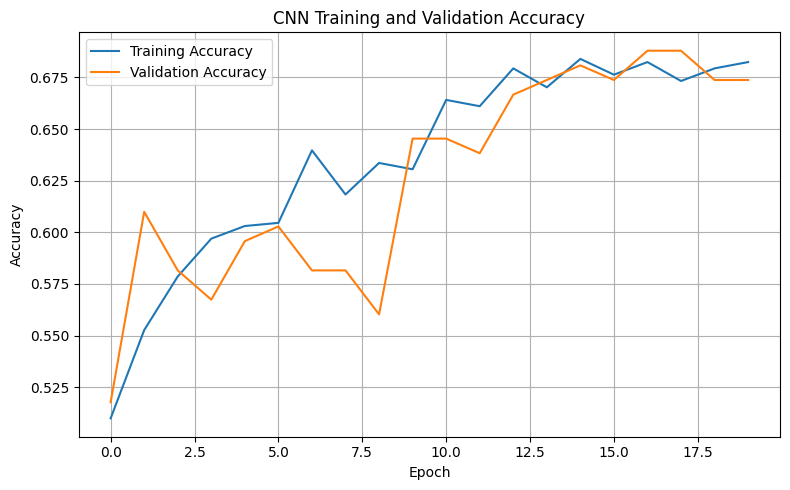

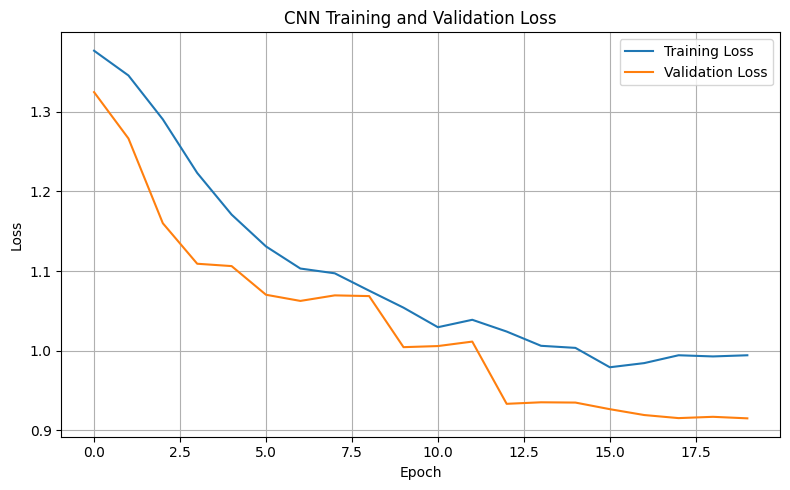

In [28]:

import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [29]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

test_loss, test_accuracy = model.evaluate(
    X_test_img, y_test_num, verbose=1
)

test_probs = model.predict(X_test_img, verbose=0)
test_preds = np.argmax(test_probs, axis=1)

class_names = [
    "Cordana", "Healthy", "Pestalotiopsis", "Sigatoka"
]

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_num,
    test_preds,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_num, test_preds, labels=[0, 1, 2, 3]))


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6738 - loss: 0.9521
Test Accuracy: 67.38%
Test Loss: 0.9521

Classification Report:
                precision    recall  f1-score   support

       Cordana     0.6452    0.8000    0.7143        25
       Healthy     0.4286    0.4737    0.4500        19
Pestalotiopsis     0.3939    0.5000    0.4407        26
      Sigatoka     0.9464    0.7465    0.8346        71

      accuracy                         0.6738       141
     macro avg     0.6035    0.6300    0.6099       141
  weighted avg     0.7214    0.6738    0.6888       141

Confusion Matrix:
[[20  2  1  2]
 [ 0  9  9  1]
 [ 3 10 13  0]
 [ 8  0 10 53]]


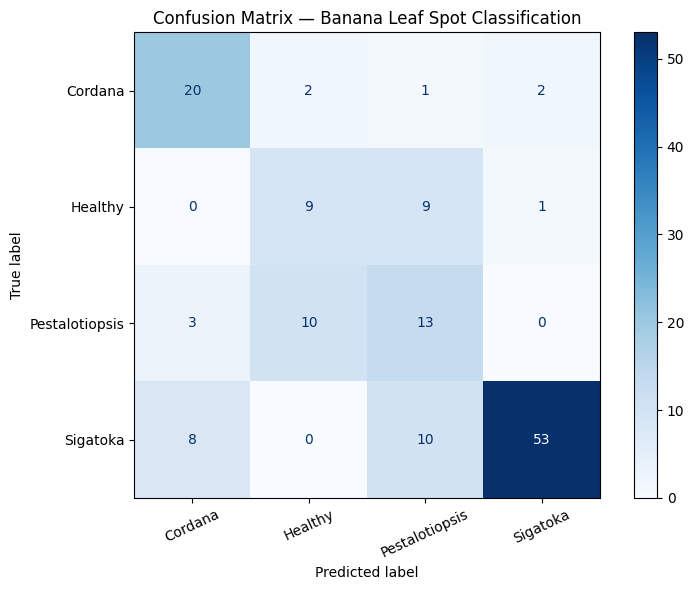

In [30]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

class_names = [
    "Cordana", "Healthy", "Pestalotiopsis", "Sigatoka"
]

cm = confusion_matrix(
    y_test_num,
    test_preds,
    labels=[0, 1, 2, 3]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
display.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Banana Leaf Spot Classification")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
